# Tic-Tac-Toe: Dynamic Programming vs Reinforcement Learning

**Question:** if an agent learns tic-tac-toe by playing a random opponent, how good does it really get, and can a smarter opponent beat it?

This project compares two ways of learning to play as X (moving first):
- **Value iteration:** solves the game as a Markov Decision Process, using a full model of the opponent
- **Q-learning:** learns from experience by playing thousands of games, with no model

They're compared with a **random player** and a **perfect minimax player**, and tested against both. The code is in [`game.py`](game.py) and [`agents.py`](agents.py), with tests in [`tests/`](tests/).

## 1. Setup

In [1]:
import random
from functools import lru_cache

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from agents import (QLearningAgent, ValueIterationAgent, _reward, minimax_agent, minimax_value,
                    play_match, random_agent, result)
from game import EMPTY, all_states, is_terminal, legal_moves, play, show, to_move, winner

WIN, DRAW, LOSS = "#1baf7a", "#2a78d6", "#eb6834"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK,
})
IMG = "images"

## 2. The game and its state space

In [2]:
states = all_states()
x_turn = [s for s in states if not is_terminal(s) and to_move(s) == "X"]
print(f"Legal board positions:              {len(states):,}")
print(f"Non-terminal positions with X to move: {len(x_turn):,}  (the states X has to decide in)")
print(f"Value of the game with perfect play:  {minimax_value(EMPTY)}  (0 = draw)")

Legal board positions:              5,478
Non-terminal positions with X to move: 2,423  (the states X has to decide in)
Value of the game with perfect play:  0  (0 = draw)


There are only **5,478** legal positions, so both methods can store a value for every one in a table. Perfect play by both sides always ends in a **draw**, so the best any X agent can guarantee against a perfect opponent is a draw.

## 3. Value iteration (dynamic programming)

**The MDP, from X's point of view:**

| Part | Definition |
|---|---|
| States | Non-terminal boards where it's X's turn (2,423) |
| Actions | Any empty cell |
| Transitions | X plays, then O picks one of the remaining empty cells uniformly at random |
| Rewards | +1 if X wins, -1 if O wins, 0 for a draw, all given on the move that ends the game; 0 otherwise |
| Discount | gamma = 1 (games are at most 9 moves long) |

Value iteration repeatedly applies the Bellman optimality update until the values stop changing:

$$V(s) = \max_a \sum_{s'} P(s' \mid s,a)\,\big[R(s,a,s') + \gamma V(s')\big], \qquad V(\text{terminal}) = 0$$

Because terminal boards have value 0, every final reward is counted exactly once. So V(s) = P(win) - P(loss) from s, and it always stays between -1 and +1.

In [3]:
vi = ValueIterationAgent().solve()
print(f"Converged in {vi.sweeps} sweeps")
print(f"V(empty board) = {vi.V[EMPTY]:.4f}   ->   best first move: cell {vi.policy[EMPTY]} (top-left corner)\n")

tests = {
    "X can win (top row)":       tuple("XX  O O  "),
    "O threatens the top row":   tuple("OO  X   X"),
    "Win beats blocking":        tuple("X X OO   "),
}
for label, b in tests.items():
    print(f"{label}: plays cell {vi(b)}  (value {vi.V[b]:+.3f})")
    print(show(b), "\n")

Converged in 4 sweeps
V(empty board) = 0.9948   ->   best first move: cell 0 (top-left corner)

X can win (top row): plays cell 2  (value +1.000)
X | X |  
---------
  | O |  
---------
O |   |   

O threatens the top row: plays cell 2  (value +1.000)
O | O |  
---------
  | X |  
---------
  |   | X 

Win beats blocking: plays cell 1  (value +1.000)
X |   | X
---------
  | O | O
---------
  |   |   



## 4. Q-learning (reinforcement learning)

Q-learning learns a value Q(s, a) for each board and move just by playing, with no model of the opponent:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,\big[r + \gamma \max_{a'} Q(s',a') - Q(s,a)\big]$$

When the game ends there is no next state, so the target is just the final reward. The agent plays X against a random O, choosing a random move with probability epsilon (exploration) and its best-known move otherwise.

**Experiment:** 4 hyperparameter settings x 5 random seeds = 20 training runs of 20,000 games each. Every 1,000 games, the agent's **greedy policy (exploration off)** plays 500 test games against a random opponent. Measuring with exploration on would understate how good the learned policy is.

In [4]:
CONFIGS = [
    {"alpha": 0.05, "gamma": 0.9,  "epsilon": 0.10},
    {"alpha": 0.10, "gamma": 0.95, "epsilon": 0.20},
    {"alpha": 0.30, "gamma": 0.9,  "epsilon": 0.05},
    {"alpha": 0.50, "gamma": 0.8,  "epsilon": 0.15},
]
SEEDS, EPISODES, EVERY, TEST_GAMES = range(5), 20_000, 1_000, 500

def label(c):
    return f"alpha={c['alpha']}, gamma={c['gamma']}, eps={c['epsilon']}"

curves, runs = [], []
for c in CONFIGS:
    for seed in SEEDS:
        agent = QLearningAgent(**c, seed=seed)
        for ep in range(1, EPISODES + 1):
            agent.train_episode()
            if ep % EVERY == 0:
                eps, agent.epsilon = agent.epsilon, 0
                curves.append({"config": label(c), "seed": seed, "episode": ep,
                               **play_match(agent, random_agent, TEST_GAMES, seed=ep)})
                agent.epsilon = eps
        agent.epsilon = 0
        runs.append({"config": label(c), "seed": seed, "agent": agent})
curves = pd.DataFrame(curves)
final = (curves[curves["episode"] == EPISODES].groupby("config")[["win", "draw", "loss"]]
         .agg(["mean", "min", "max"]).round(3))
final

win                 draw                \
                                 mean    min    max   mean    min    max   
config                                                                     
alpha=0.05, gamma=0.9, eps=0.1  0.944  0.910  0.960  0.044  0.020  0.062   
alpha=0.1, gamma=0.95, eps=0.2  0.967  0.954  0.978  0.025  0.020  0.036   
alpha=0.3, gamma=0.9, eps=0.05  0.983  0.968  0.990  0.015  0.010  0.022   
alpha=0.5, gamma=0.8, eps=0.15  0.978  0.948  0.994  0.016  0.004  0.038   

                                 loss              
                                 mean  min    max  
config                                             
alpha=0.05, gamma=0.9, eps=0.1  0.013  0.0  0.036  
alpha=0.1, gamma=0.95, eps=0.2  0.008  0.0  0.022  
alpha=0.3, gamma=0.9, eps=0.05  0.002  0.0  0.010  
alpha=0.5, gamma=0.8, eps=0.15  0.007  0.0  0.014

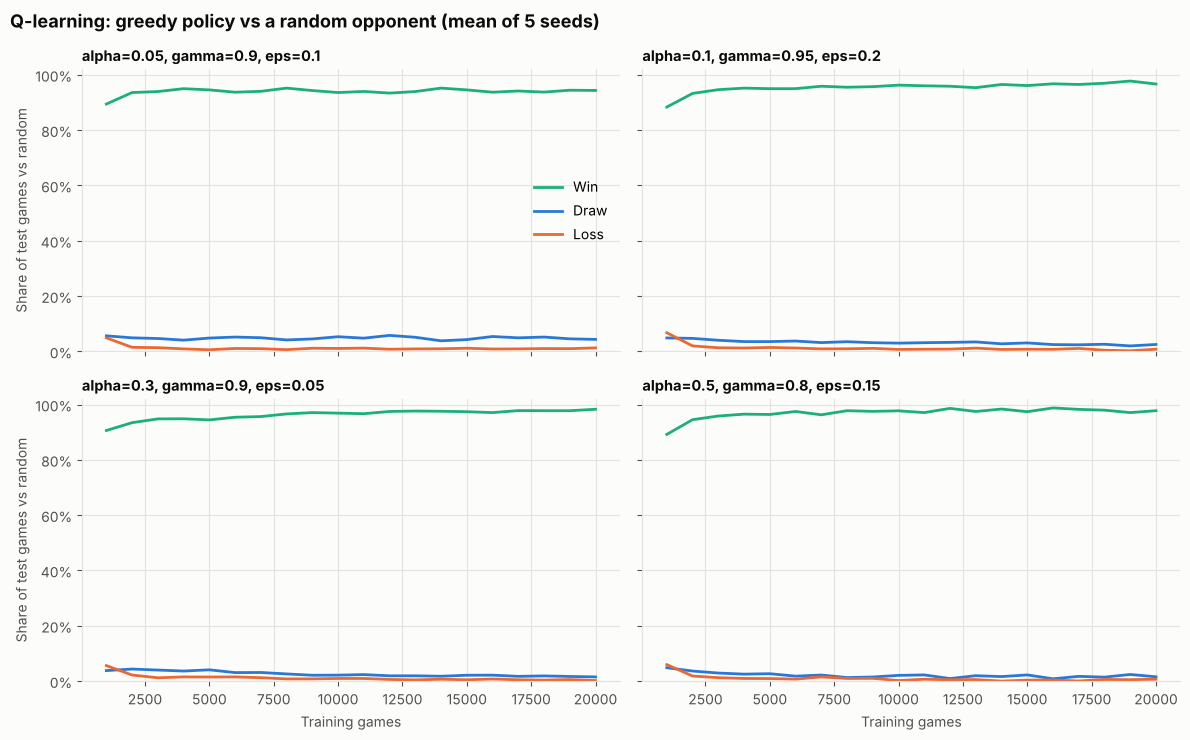

In [5]:
mean_curves = curves.groupby(["config", "episode"])[["win", "draw", "loss"]].mean().reset_index()
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True, sharey=True)
for ax, c in zip(axes.flat, CONFIGS):
    d = mean_curves[mean_curves["config"] == label(c)]
    for col, colour, name in [("win", WIN, "Win"), ("draw", DRAW, "Draw"), ("loss", LOSS, "Loss")]:
        ax.plot(d["episode"], d[col], color=colour, linewidth=2, label=name)
    ax.set_title(label(c), loc="left", fontsize=10.5)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_ylim(0, 1.02)
for ax in axes[1]:
    ax.set_xlabel("Training games")
for ax in axes[:, 0]:
    ax.set_ylabel("Share of test games vs random")
axes[0, 0].legend(frameon=False, loc="center right")
fig.suptitle("Q-learning: greedy policy vs a random opponent (mean of 5 seeds)", x=0.01, ha="left",
             fontsize=13, fontweight="bold", color=INK)
plt.tight_layout()
plt.savefig(f"{IMG}/q_learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

**Observations**
- **Q-learning learns fast.** After only 1,000 training games, the greedy policy already wins about 89 to 91% of games against a random opponent.
- **The best setting is alpha = 0.3, gamma = 0.9, epsilon = 0.05**, with a mean final win rate of 98.3% and a 0.2% loss rate. The slowest learner, alpha = 0.05, finishes at 94.4%.
- **Losses don't disappear completely.** The mean final loss rate is 0.2 to 1.3% depending on the setting, so the policy still has some gaps.
- **Results vary between seeds:** final win rates range from 91% to 99% across runs. That's why each setting was run 5 times.

## 5. What went wrong in my first version

My original coursework version had two bugs that made the results look better than they were:

1. **Losses were recorded as draws.** The training loop only stored the winner when X ended the game. When O won, the winner stayed empty and the game was logged as a draw, so the loss rate on every chart was always 0%.
2. **Value iteration counted the final reward twice:** once as the reward, and again because terminal boards were given a value equal to that reward. That's why the empty board's value came out as 1.99, which is impossible when rewards are between -1 and +1.

This replays both. First, the loss-recording bug, using the original training loop's logic and tracking what it **recorded** against what **actually happened**:

Recorded loss rate, all blocks:     max 0.0%
Actual loss rate, first 1,000 games: 11.5%
Actual loss rate, last 1,000 games:  2.4%  (exploration still on)


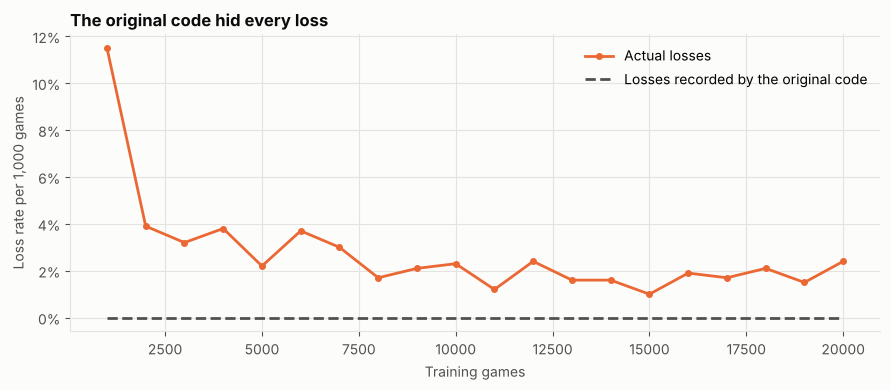

In [6]:
def original_style_training(c, episodes=EPISODES, seed=0):
    agent = QLearningAgent(**c, seed=seed)
    log = []
    for ep in range(episodes):
        true = agent.train_episode()
        # The original code only stored a winner when X's move ended the game, so an O win looked like a draw
        recorded = "loss->draw" if true == "loss" else true
        log.append((true, recorded))
    df = pd.DataFrame(log, columns=["true", "recorded"])
    df["block"] = df.index // EVERY
    return df.groupby("block").agg(true_loss=("true", lambda s: (s == "loss").mean()),
                                   recorded_loss=("recorded", lambda s: (s == "loss").mean()))

replay = original_style_training(CONFIGS[2])
print(f"Recorded loss rate, all blocks:     max {replay['recorded_loss'].max():.1%}")
print(f"Actual loss rate, first 1,000 games: {replay['true_loss'].iloc[0]:.1%}")
print(f"Actual loss rate, last 1,000 games:  {replay['true_loss'].iloc[-1]:.1%}  (exploration still on)")

fig, ax = plt.subplots(figsize=(9, 4))
x = (replay.index + 1) * EVERY
ax.plot(x, replay["true_loss"], color=LOSS, linewidth=2, marker="o", markersize=4, label="Actual losses")
ax.plot(x, replay["recorded_loss"], color=INK2, linewidth=2, linestyle="--", label="Losses recorded by the original code")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Training games")
ax.set_ylabel("Loss rate per 1,000 games")
ax.set_title("The original code hid every loss", loc="left")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(f"{IMG}/loss_bug.png", dpi=150, bbox_inches="tight")
plt.show()

Second, the double-counted reward. This re-runs value iteration with terminal boards valued at their payoff, as in the original:

In [7]:
class DoubleCountVI(ValueIterationAgent):
    def q(self, s, a):
        total = 0.0
        for p, r, n in self._outcomes(s, a):
            # terminal boards get their payoff as a value as well as the reward, so it's counted twice
            total += p * (r + (self.V[n] if n else r))
        return total

bad = DoubleCountVI().solve()
print(f"V(empty), original formulation: {bad.V[EMPTY]:.4f}")
print(f"V(empty), fixed:                {vi.V[EMPTY]:.4f}")
same = sum(bad.policy[s] == vi.policy[s] for s in vi.states)
print(f"Same move chosen in {same:,} of {len(vi.states):,} states")

V(empty), original formulation: 1.9896
V(empty), fixed:                0.9948
Same move chosen in 2,417 of 2,423 states


**Observations**
- **The original code recorded a 0% loss rate in every block of 1,000 games,** but the agent actually lost 11.5% of its first 1,000 games while it was still learning. The "losses dropped to near 0%" conclusion in my first version came from the bug, not the learning.
- **The double-counted reward inflated the empty board's value to 1.99,** against the correct 0.995. It only changed the chosen move in 6 of 2,423 positions, because doubling every final reward mostly keeps the same ranking of moves. But the values themselves were meaningless.
- **The lesson:** sanity-check numbers against what's possible. A loss rate of exactly zero during early training, or a value above the maximum reward, should have been a red flag.

## 6. Head to head: who beats whom?

Each agent plays X in 5,000 games against two opponents:
- **a random player**, which is what both learning agents were trained against
- **a perfect minimax player**, which never makes a mistake (it picks randomly between equally good moves)

The Q-learning agent shown is the first run (seed 0) of the setting with the best final win rate.

In [8]:
best_cfg = final[("win", "mean")].idxmax()
q_best = next(r["agent"] for r in runs if r["config"] == best_cfg and r["seed"] == 0)
players = {"Value iteration": vi, "Q-learning": q_best, "Minimax (perfect)": minimax_agent, "Random": random_agent}

rows = []
for name, agent in players.items():
    for opp_name, opp in [("vs random O", random_agent), ("vs perfect O", minimax_agent)]:
        rows.append({"agent": name, "opponent": opp_name, **play_match(agent, opp, 5000, seed=7)})
h2h = pd.DataFrame(rows)
print("Q-learning setting:", best_cfg)
h2h.pivot(index="agent", columns="opponent", values=["win", "draw", "loss"]).round(3)

Q-learning setting: alpha=0.3, gamma=0.9, eps=0.05


win                     draw              \
opponent          vs perfect O vs random O vs perfect O vs random O   
agent                                                                 
Minimax (perfect)          0.0       0.970        1.000       0.030   
Q-learning                 0.0       0.984        1.000       0.016   
Random                     0.0       0.578        0.209       0.128   
Value iteration            0.0       0.995        1.000       0.005   

                          loss              
opponent          vs perfect O vs random O  
agent                                       
Minimax (perfect)        0.000       0.000  
Q-learning               0.000       0.000  
Random                   0.791       0.293  
Value iteration          0.000       0.000

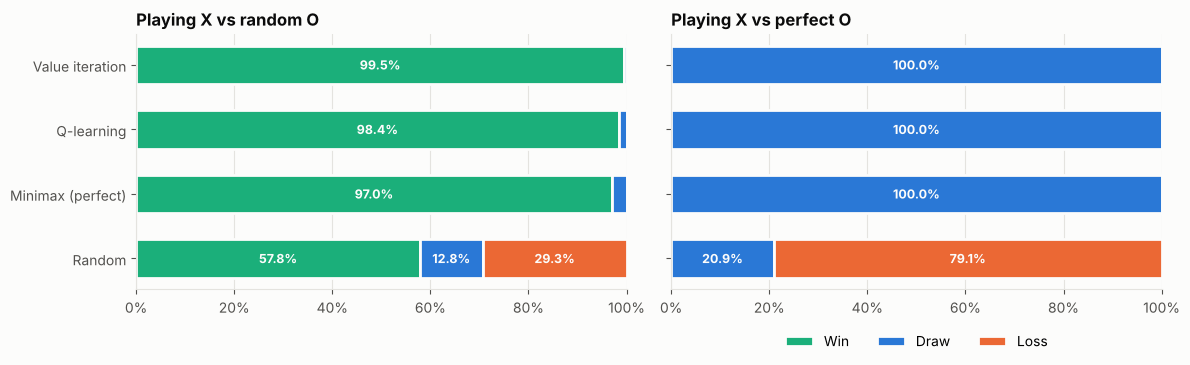

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
order = list(players)[::-1]
for ax, opp in zip(axes, ["vs random O", "vs perfect O"]):
    d = h2h[h2h["opponent"] == opp].set_index("agent").loc[order]
    left = np.zeros(len(d))
    for col, colour, name in [("win", WIN, "Win"), ("draw", DRAW, "Draw"), ("loss", LOSS, "Loss")]:
        ax.barh(d.index, d[col], left=left, color=colour, height=0.6, edgecolor="#fcfcfb", linewidth=2, label=name)
        for i, (l, v) in enumerate(zip(left, d[col])):
            if v >= 0.08:
                ax.text(l + v / 2, i, f"{v:.1%}", ha="center", va="center", color="#fcfcfb", fontsize=9, fontweight="bold")
        left += d[col].values
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="y", visible=False)
    ax.set_title(f"Playing X {opp}", loc="left")
axes[1].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
plt.tight_layout()
plt.savefig(f"{IMG}/head_to_head.png", dpi=150, bbox_inches="tight")
plt.show()

**Observations**
- **Against a random opponent, value iteration wins 99.5% of games,** more than the "perfect" minimax player's 97.0%. Minimax only plays to guarantee the best result against perfect play, while value iteration is specifically optimised to exploit a random opponent's mistakes.
- **Q-learning gets close to value iteration (98.4%)** without ever being given the rules of how the opponent moves.
- **Against the perfect player, every learned agent draws 100% of games,** which is the best possible result. A random player loses 79% of the time.

## 7. Can a smart opponent beat them? Exact worst case

Playing sample games can miss rare weaknesses. Because the game is small, we can check exactly: for a fixed X policy, search **every possible sequence of O moves** and find the worst result X can be forced into. A worst case of 0 means the agent can never lose, to anyone. A worst case of -1 means some opponent can beat it.

In [10]:
def worst_case(policy):
    @lru_cache(maxsize=None)
    def w(b):
        if is_terminal(b):
            return int(_reward(b))
        if to_move(b) == "X":
            return w(play(b, policy(b)))
        return min(w(play(b, m)) for m in legal_moves(b))
    return w(EMPTY)

fixed = lambda agent: (lambda b: agent.greedy(b, random.Random(0)))   # fix tie-breaks so the policy is deterministic
print(f"Value iteration worst case: {worst_case(lambda b: vi.policy[b]):+d}")

wc = pd.DataFrame([{"config": r["config"], "seed": r["seed"], "worst_case": worst_case(fixed(r["agent"])),
                    "win_vs_random": curves[(curves.config == r["config"]) & (curves.seed == r["seed"])
                                            & (curves.episode == EPISODES)]["win"].iloc[0]} for r in runs])
summary = wc.groupby("config").agg(runs=("seed", "size"), beatable=("worst_case", lambda s: (s < 0).sum()),
                                   mean_win_vs_random=("win_vs_random", "mean"))
print(f"Q-learning runs that some opponent can beat: {(wc['worst_case'] < 0).sum()} of {len(wc)}\n")
summary.round(3)

Value iteration worst case: +0
Q-learning runs that some opponent can beat: 11 of 20



,runs,beatable,mean_win_vs_random
config,,,
"alpha=0.05, gamma=0.9, eps=0.1",5,3,0.944
"alpha=0.1, gamma=0.95, eps=0.2",5,2,0.967
"alpha=0.3, gamma=0.9, eps=0.05",5,2,0.983
"alpha=0.5, gamma=0.8, eps=0.15",5,4,0.978


**Observations**
- **Value iteration can never lose, to any opponent.** Its exact worst case is a draw.
- **11 of the 20 Q-learning agents can be beaten by the right sequence of moves,** even though they all win 91 to 99% against a random player. A random opponent rarely plays the strong lines that would expose their weak spots, so those positions are barely explored during training.
- **Even the best setting had 2 beatable runs out of 5.** The head-to-head games above happened to use one of the unbeatable runs, which is why its 5,000 sample games against minimax showed no losses.
- **The lesson:** a high win rate against the opponent you trained on says little about robustness. Testing against a strong opponent, or checking exactly as here, is essential.

## 8. Conclusions

| Question | Answer |
|---|---|
| Which method plays best against a random opponent? | Value iteration (99.5% wins), ahead of Q-learning (98.4%) and even minimax (97.0%) |
| Can a perfect opponent beat them? | Value iteration never loses to anyone. 11 of 20 Q-learning agents can be beaten |
| Why the difference? | Value iteration uses a complete model and covers every position. Q-learning only learns positions it happens to visit |
| When would you use Q-learning? | When there's no model of the environment, which is most real problems, but then you need strong opponents or self-play in training |
| What did I fix? | Losses hidden as draws, double-counted rewards, missing turn information, and the missing method comparison |

## 9. Limitations
- **Only one opponent model.** Both learners were trained against a random player. Training against minimax, or by self-play, would teach them to defend against strong moves, and is the obvious next step.
- **The agents only play X (first).** Playing second is harder, because O can only hope to draw against good play.
- **Tabular methods don't scale.** A table for each position works for 5,478 positions, but not for chess or Go, which need function approximation (e.g. deep Q-networks).

## References
[1] R. S. Sutton and A. G. Barto, *Reinforcement Learning: An Introduction*, 2nd ed. MIT Press, 2018.

[2] C. J. C. H. Watkins and P. Dayan, "Q-learning," *Machine Learning*, vol. 8, pp. 279–292, 1992.